# Neural-Network House Price Regression: what the network needs, and where it still loses

**The question:** predict the typical house price in a neighbourhood from eight facts about it (income, house age, rooms, location, and so on). A small neural network can do this. But the interesting questions are the ones the headline error hides: *what does the network need to learn at all, how much does its size matter, does it beat older and simpler tools, and where on the map does it go wrong?*

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit the data
4. Hypotheses and why we chose each test
5. H1: what drives house value?
6. Training the network
7. H2: does standardising the inputs matter?
8. H3: does the network beat simpler models?
9. H4: does the size of the network matter?
10. H5: where does the best model go wrong?
11. Takeaways
12. Limitations

**Run it:** `uv run jupyter lab DL/housing-regression-nn/housing_regression_nn.ipynb`, or *Run All* in any Jupyter. The data (about 1 MB) downloads itself on the first run. It uses a GPU if present and takes about 6 minutes on one.

## 1. 💡 The simple analogy

Imagine a **real-estate agent in training** who has seen thousands of neighbourhoods and the price each one sold at.

- A **linear model** is an agent with a simple rule of thumb: "add so much per dollar of income, subtract so much for age". Easy to explain, but it can only add things up.
- A **neural network** is an agent who builds her own *combinations*: "high income **and** near the coast **and** small households means very expensive". The hidden layers are where she builds these combos, and a bigger network can hold more of them.
- **Standardising** is like putting every fact in comparable units. If one fact is measured in thousands (population) and another in single digits (rooms), the agent pays attention to the loud numbers and ignores the quiet ones until she is told to listen to all of them equally.
- The **price ceiling** is a sign on the data: "anything over $500k is recorded as $500k". An agent trained on that sign will never learn that some neighbourhoods are worth far more.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the number of training runs and the training recipe keeps the notebook reproducible and avoids "magic numbers". The main network's shape, **two hidden layers of 64**, is fixed here *before* looking at any result.

In [1]:
import contextlib
import copy
import io
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from scipy import stats
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from torch import nn

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
SEED = 365
N_BOOTSTRAP = 2_000
N_SEEDS = 10  # trainings per setting for the paired raw-vs-standardised test
N_SEEDS_ARCH = 5  # trainings per architecture
EPOCHS = 80
BATCH = 512
LEARNING_RATE = 2e-3
REFERENCE_LAYERS = (64, 64)  # chosen before looking at any result
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if p < 1e-300 else f"{p:.1e}"

## 3. Audit the data first

*What:* load the **California housing** data (one row per census district: 20,640 districts, eight features, and the median house value) and split it **60% train / 20% validation / 20% test**. Inputs are standardised using the training rows only.

*Why this dataset?* The Boston housing data used by the legacy notebook was **removed from scikit-learn** over an ethical problem in one of its columns, so it cannot be loaded any more. California housing is its standard replacement: bigger, and with location included.

> **Problems in the legacy notebook this replaces:** it used `load_boston` (removed), the `keras.wrappers.scikit_learn` wrapper (removed), and, most importantly, it built a **"standardised" pipeline but then evaluated the unstandardised `estimator` instead** in all three experiments, so standardising was never actually applied. It also reported a single 10-fold run per model with no baseline, no comparison to simpler models and no statistical test.

In [2]:
def load_housing() -> pd.DataFrame:
    """Loads the California housing districts (downloaded once into ``data/``).

    Returns:
        One row per census district: eight features plus ``MedHouseVal`` in units of $100,000.

    Raises:
        ValueError: If the table does not have the expected shape or has missing values.
    """
    with contextlib.redirect_stderr(io.StringIO()):
        frame = fetch_california_housing(data_home=DATA_DIR, as_frame=True).frame
    if frame.shape != (20_640, 9) or frame.isna().any().any():
        raise ValueError("Unexpected California housing table")
    return frame


housing = load_housing()
FEATURES = [c for c in housing.columns if c != "MedHouseVal"]
TARGET = "MedHouseVal"
n_rows = len(housing)
cap = housing[TARGET].max()
capped = housing[TARGET] >= cap
print(f"{n_rows:,} districts, {len(FEATURES)} features, no missing values")
print(
    f"Median house value: mean ${housing[TARGET].mean() * 100:.0f}k, "
    f"sd ${housing[TARGET].std() * 100:.0f}k, range ${housing[TARGET].min() * 100:.0f}k to "
    f"${cap * 100:.0f}k"
)
print(
    f"Districts sitting exactly at the ${cap * 100:.0f}k ceiling: {capped.sum():,} "
    f"({capped.mean():.1%})"
)
spread = housing[FEATURES].describe().T[["mean", "std", "min", "max"]]
print(spread.round(2).to_string())
print(
    f"\nGuessing the average for everyone: RMSE = {housing[TARGET].std():.3f} "
    f"(about ${housing[TARGET].std() * 100:.0f}k)"
)

train_idx, rest_idx = train_test_split(np.arange(n_rows), test_size=0.4, random_state=SEED)
val_idx, test_idx = train_test_split(rest_idx, test_size=0.5, random_state=SEED)
X_all = housing[FEATURES].to_numpy(dtype=np.float32)
y_all = housing[TARGET].to_numpy(dtype=np.float32)
X_train, X_val, X_test = X_all[train_idx], X_all[val_idx], X_all[test_idx]
y_train, y_val, y_test = y_all[train_idx], y_all[val_idx], y_all[test_idx]
scaler = StandardScaler().fit(X_train)  # fitted on the training rows only
Z_train, Z_val, Z_test = (scaler.transform(a).astype(np.float32) for a in (X_train, X_val, X_test))
print(f"\nTrain {len(train_idx):,}, validation {len(val_idx):,}, test {len(test_idx):,}")

20,640 districts, 8 features, no missing values
Median house value: mean $207k, sd $115k, range $15k to $500k
Districts sitting exactly at the $500k ceiling: 965 (4.7%)
               mean      std     min       max
MedInc         3.87     1.90    0.50     15.00
HouseAge      28.64    12.59    1.00     52.00
AveRooms       5.43     2.47    0.85    141.91
AveBedrms      1.10     0.47    0.33     34.07
Population  1425.48  1132.46    3.00  35682.00
AveOccup       3.07    10.39    0.69   1243.33
Latitude      35.63     2.14   32.54     41.95
Longitude   -119.57     2.00 -124.35   -114.31

Guessing the average for everyone: RMSE = 1.154 (about $115k)

Train 12,384, validation 4,128, test 4,128


**How to read this:**

- **20,640 districts, 8 features, no missing values.** The target is the median house value in units of $100,000: the mean is **$207k**, the standard deviation **$115k**, ranging from **$15k to $500k**.
- **A ceiling is hiding in the target:** **965 districts (4.7%)** sit at exactly **$500k**. The real values are higher but were recorded as $500k, which will come back in H5.
- **The features live on wildly different scales:** population averages 1,425 and reaches 35,682; the average number of rooms is 5.4 but reaches 141.9; the average household size is 3.1 but reaches 1,243. These extreme values look like tiny or unusual districts, not typos, so we keep them but pay attention (H2).
- **The yardstick:** guessing the average for everyone gives an RMSE of **1.154**, about **$115k**. Any model should beat that.
- The split: **12,384** train, **4,128** validation, **4,128** test districts.

## 4. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | What drives house value? | No monotonic link between a feature and value | A link exists | Spearman ρ with bootstrap CI; Mann-Whitney for west vs east |
| H2 | Does standardising the inputs help the network? | Same test error | Lower with standardising | 10 paired seeds, Wilcoxon, bootstrap CI |
| H3 | Does the network beat simpler models? | Same RMSE as linear regression or gradient-boosted trees | Differs | Paired bootstrap of RMSE differences on the same test districts |
| H4 | Does network size matter? | Same RMSE for every architecture | Differs | Kruskal-Wallis, ε², paired seeds against the baseline |
| H5 | Are errors random? | Errors of neighbouring districts are unrelated | They are related | Permutation test on the correlation of each district's error with its 10 nearest neighbours; Mann-Whitney at the ceiling |

*Why these tests?* Prices and incomes are skewed, so rank-based tests (Spearman, Mann-Whitney, Wilcoxon, Kruskal-Wallis) are safer than tests that assume a bell curve. Bootstraps give honest intervals without formulas. With 20,640 rows, nearly *everything* is statistically significant, so we always look at the **size** of the effect, not just the p-value.

## 5. H1: what drives house value?

*What:* the rank correlation (**Spearman ρ**: +1 means they rise together, -1 opposite, 0 unrelated) between each feature and the house value, with a bootstrap 95% interval. And a geographic split: districts west of longitude -121.5 (roughly the coast and Bay Area side) against the rest, compared with Mann-Whitney U and **Cliff's δ** (an effect size).

*Why:* before building any model it is worth knowing what the data says, so we can tell afterwards whether the model found it.

In [3]:
def spearman_with_ci(x: np.ndarray, y: np.ndarray, n_boot: int = 500) -> tuple[float, float, float]:
    """Spearman rank correlation with a bootstrap 95% interval.

    Args:
        x: One feature.
        y: The target.
        n_boot: Number of bootstrap resamples.

    Returns:
        The correlation and the lower and upper ends of its interval.
    """
    rho = stats.spearmanr(x, y).statistic
    draws = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(x), len(x))
        draws.append(stats.spearmanr(x[pick], y[pick]).statistic)
    low, high = np.percentile(draws, [2.5, 97.5])
    return float(rho), float(low), float(high)


corr_rows = [
    (f, *spearman_with_ci(housing[f].to_numpy(), housing[TARGET].to_numpy())) for f in FEATURES
]
corr = pd.DataFrame(corr_rows, columns=["feature", "rho", "ci_low", "ci_high"]).set_index("feature")
print(corr.sort_values("rho", key=np.abs, ascending=False).round(3).to_string())

west = housing[housing["Longitude"] < -121.5][TARGET]
east = housing[housing["Longitude"] >= -121.5][TARGET]
mw = stats.mannwhitneyu(west, east)
cliff = 2 * mw.statistic / (len(west) * len(east)) - 1
print(
    f"\nWest of longitude -121.5 ({len(west):,} districts) vs east ({len(east):,}): "
    f"median ${west.median() * 100:.0f}k vs ${east.median() * 100:.0f}k; "
    f"Mann-Whitney p = {fmt_p(mw.pvalue)}, Cliff's delta = {cliff:.2f}"
)

              rho  ci_low  ci_high
feature                           
MedInc      0.677   0.668    0.686
AveRooms    0.263   0.251    0.276
AveOccup   -0.257  -0.269   -0.243
Latitude   -0.166  -0.178   -0.151
AveBedrms  -0.125  -0.139   -0.111
HouseAge    0.075   0.061    0.089
Longitude  -0.070  -0.083   -0.055
Population  0.004  -0.009    0.018

West of longitude -121.5 (5,718 districts) vs east (14,922): median $224k vs $168k; Mann-Whitney p = 5.2e-127, Cliff's delta = 0.22


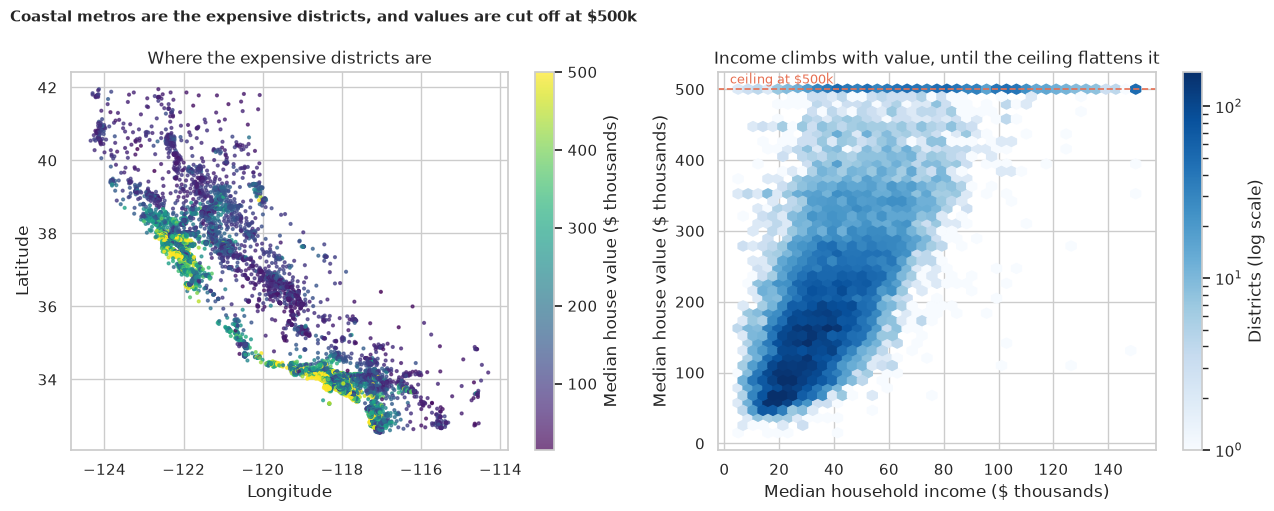

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1, 1]})
sc = axes[0].scatter(
    housing["Longitude"],
    housing["Latitude"],
    c=housing[TARGET] * 100,
    s=4,
    cmap="viridis",
    alpha=0.7,
)
fig.colorbar(sc, ax=axes[0], label="Median house value ($ thousands)")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].set_title("Where the expensive districts are")
hb = axes[1].hexbin(
    housing["MedInc"] * 10, housing[TARGET] * 100, gridsize=40, cmap="Blues", mincnt=1, bins="log"
)
fig.colorbar(hb, ax=axes[1], label="Districts (log scale)")
axes[1].axhline(cap * 100, color=ORANGE, ls="--", lw=1.2)
axes[1].text(2, cap * 100 + 8, f"ceiling at ${cap * 100:.0f}k", color=ORANGE, fontsize=9)
axes[1].set_xlabel("Median household income ($ thousands)")
axes[1].set_ylabel("Median house value ($ thousands)")
axes[1].set_title("Income climbs with value, until the ceiling flattens it")
fig.suptitle(
    f"Coastal metros are the expensive districts, and values are cut off at ${cap * 100:.0f}k",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_overview.png", dpi=150)
plt.show()

**How to read this:**

- **Income is the dominant driver:** ρ = **0.677** (95% CI 0.668 to 0.686). Next come rooms per household (**+0.263**) and household size (**-0.257**): bigger houses and smaller households go with higher prices.
- **Location matters:** latitude has ρ = **-0.166**, and the west side has a median value of **$224k** against **$168k** for the east (Mann-Whitney p = 5e-127, Cliff's δ = 0.22, a small-to-medium effect). We reject H₀ for both.
- **Population is unrelated:** ρ = **0.004** (CI -0.009 to 0.018), so **we fail to reject H₀** for that one: how many people live in a district says nothing about its prices.
- The map and hexbin show the pattern: the coastal metros are the expensive districts, and the income-to-value cloud flattens at the **$500k** ceiling, which will cap what any model can learn at the top end.

## 6. Training the network

*What:* a fully connected network (`8 → 64 → 64 → 1`, ReLU), trained with Adam (learning rate 0.002, batches of 512, up to 80 epochs) to minimise the mean squared error. After every epoch we measure the error on the **validation** rows and keep the weights from the **best validation epoch** ("early stopping"). The test rows are never looked at while training, so picking the best epoch cannot leak into the test score.

*Why this recipe?* It replaces the legacy notebook's fixed 50 or 100 epochs and batch size of 5 with a data-driven stopping point and a batch size that makes better use of the hardware.

In [5]:
def make_mlp(n_inputs: int, hidden: tuple[int, ...]) -> nn.Sequential:
    """A fully connected network with ReLU layers and one output (the predicted value).

    Args:
        n_inputs: Number of input features.
        hidden: Width of each hidden layer.

    Returns:
        The untrained network.
    """
    layers: list[nn.Module] = []
    width = n_inputs
    for size in hidden:
        layers += [nn.Linear(width, size), nn.ReLU()]
        width = size
    layers.append(nn.Linear(width, 1))
    return nn.Sequential(*layers)


def rmse_of(model: nn.Module, x: torch.Tensor, y: torch.Tensor) -> float:
    """Root-mean-squared error of a model on a set of rows."""
    model.eval()
    with torch.no_grad():
        return float(((model(x).squeeze(1) - y) ** 2).mean().sqrt())


def fit_mlp(
    train_x: np.ndarray, val_x: np.ndarray, hidden: tuple[int, ...], seed: int
) -> tuple[nn.Sequential, pd.DataFrame, int]:
    """Trains an MLP with Adam and keeps the weights from the best validation epoch.

    The test rows are never touched here, so choosing the epoch cannot leak into the test score.

    Args:
        train_x: Training features (already scaled or not, as the caller decides).
        val_x: Validation features, prepared the same way.
        hidden: Hidden layer widths.
        seed: Random seed for the weights and the batch order.

    Returns:
        The model at its best validation epoch, a per-epoch loss table and that epoch's number.
    """
    torch.manual_seed(seed)
    model = make_mlp(train_x.shape[1], hidden).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    xt = torch.tensor(train_x, device=DEVICE)
    yt = torch.tensor(y_train, device=DEVICE)
    xv = torch.tensor(val_x, device=DEVICE)
    yv = torch.tensor(y_val, device=DEVICE)
    best_state, best_val, best_epoch, rows = None, float("inf"), 0, []
    for epoch in range(1, EPOCHS + 1):
        model.train()
        order = torch.randperm(len(xt), device=DEVICE)
        for start in range(0, len(xt), BATCH):
            pick = order[start : start + BATCH]
            loss = nn.functional.mse_loss(model(xt[pick]).squeeze(1), yt[pick])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        val_rmse = rmse_of(model, xv, yv)
        rows.append({"epoch": epoch, "train": rmse_of(model, xt, yt), "validation": val_rmse})
        if val_rmse < best_val:
            best_val, best_epoch, best_state = val_rmse, epoch, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model, pd.DataFrame(rows), best_epoch


def predict(model: nn.Module, features: np.ndarray) -> np.ndarray:
    """Predictions of a trained model for a feature matrix.

    Args:
        model: A trained network.
        features: Rows prepared the same way as the training rows.

    Returns:
        Predicted values, shape (n,).
    """
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(features, device=DEVICE)).squeeze(1).cpu().numpy()


def rmse(pred: np.ndarray, truth: np.ndarray) -> float:
    """Root-mean-squared error between predictions and truth."""
    return float(np.sqrt(np.mean((pred - truth) ** 2)))


reference, ref_history, ref_epoch = fit_mlp(Z_train, Z_val, REFERENCE_LAYERS, seed=0)
n_weights = sum(p.numel() for p in reference.parameters())
print(
    f"Reference network {REFERENCE_LAYERS}: {n_weights:,} weights; best validation epoch "
    f"{ref_epoch} of {EPOCHS}"
)
print(
    f"Train RMSE {ref_history['train'].iloc[ref_epoch - 1]:.3f}, validation RMSE "
    f"{ref_history['validation'].iloc[ref_epoch - 1]:.3f}, "
    f"test RMSE {rmse(predict(reference, Z_test), y_test):.3f}"
)

Reference network (64, 64): 4,801 weights; best validation epoch 73 of 80
Train RMSE 0.517, validation RMSE 0.527, test RMSE 0.541


**How to read this:**

- The reference network has **4,801 weights**, and its best validation epoch is **73 of 80** (so it was still slowly improving at the end of the budget).
- Errors: **0.517** on the training rows, **0.527** on validation, **0.541** on the test rows (about $52k to $54k). The small gap between them means it is not memorising the training data.

## 7. H2: does standardising the inputs matter?

*What:* train the same network **twice per seed**, once on the raw features and once on standardised ones (mean 0, spread 1, fitted on the training rows), for **10 seeds**. The two runs of a seed start from the same random weights and see the same batches, so the comparison is **paired**. We report the difference in test error with a bootstrap interval and a Wilcoxon signed-rank test.

*Why it should matter:* the raw features differ in size by factors of thousands. Gradient descent takes the same step size for every weight, so the large-valued features dominate the first updates and the small ones barely register. This is the step the legacy notebook *meant* to take but never did.

In [6]:
raw_rmse, std_rmse, std_models = [], [], []
for seed in range(N_SEEDS):
    model_std = reference if seed == 0 else fit_mlp(Z_train, Z_val, REFERENCE_LAYERS, seed)[0]
    model_raw = fit_mlp(X_train, X_val, REFERENCE_LAYERS, seed)[0]
    std_models.append(model_std)
    std_rmse.append(rmse(predict(model_std, Z_test), y_test))
    raw_rmse.append(rmse(predict(model_raw, X_test), y_test))
raw_rmse, std_rmse = np.array(raw_rmse), np.array(std_rmse)
diff = raw_rmse - std_rmse
diff_ci = np.percentile([rng.choice(diff, N_SEEDS).mean() for _ in range(N_BOOTSTRAP)], [2.5, 97.5])
wil = stats.wilcoxon(raw_rmse, std_rmse)
print(f"Test RMSE over {N_SEEDS} paired seeds (same weights start, same batch order):")
print(
    f"  raw features:          mean {raw_rmse.mean():.3f} (range {raw_rmse.min():.3f} to "
    f"{raw_rmse.max():.3f})"
)
print(
    f"  standardised features: mean {std_rmse.mean():.3f} (range {std_rmse.min():.3f} to "
    f"{std_rmse.max():.3f})"
)
print(
    f"Raw minus standardised: {diff.mean():+.3f} (95% bootstrap CI {diff_ci[0]:+.3f} to "
    f"{diff_ci[1]:+.3f}); standardising won in {(std_rmse < raw_rmse).sum()} of {N_SEEDS} "
    f"seeds; Wilcoxon p = {wil.pvalue:.3f}"
)

Test RMSE over 10 paired seeds (same weights start, same batch order):
  raw features:          mean 0.783 (range 0.751 to 0.810)
  standardised features: mean 0.540 (range 0.533 to 0.546)
Raw minus standardised: +0.243 (95% bootstrap CI +0.230 to +0.256); standardising won in 10 of 10 seeds; Wilcoxon p = 0.002


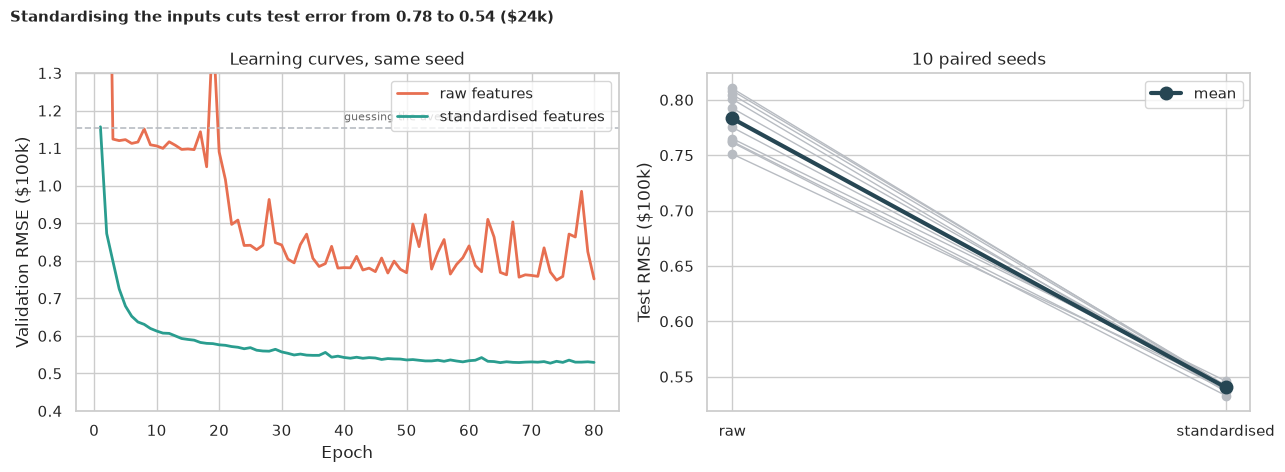

In [7]:
curve_raw = fit_mlp(X_train, X_val, REFERENCE_LAYERS, seed=0)[1]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(curve_raw["epoch"], curve_raw["validation"], color=ORANGE, lw=2, label="raw features")
axes[0].plot(
    ref_history["epoch"], ref_history["validation"], color=TEAL, lw=2, label="standardised features"
)
axes[0].axhline(y_all.std(), color=GREY, ls="--", lw=1.2)
axes[0].text(EPOCHS * 0.5, y_all.std() + 0.02, "guessing the average", color="dimgray", fontsize=8)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation RMSE ($100k)")
axes[0].set_ylim(0.4, 1.3)
axes[0].set_title("Learning curves, same seed")
axes[0].legend()
for r, s in zip(raw_rmse, std_rmse, strict=True):
    axes[1].plot([0, 1], [r, s], color=GREY, marker="o", lw=1)
axes[1].plot(
    [0, 1], [raw_rmse.mean(), std_rmse.mean()], color=NAVY, marker="o", lw=3, ms=9, label="mean"
)
axes[1].set_xticks([0, 1], ["raw", "standardised"])
axes[1].set_ylabel("Test RMSE ($100k)")
axes[1].set_title(f"{N_SEEDS} paired seeds")
axes[1].legend()
fig.suptitle(
    f"Standardising the inputs cuts test error from {raw_rmse.mean():.2f} to "
    f"{std_rmse.mean():.2f} (${diff.mean() * 100:.0f}k)",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_standardising.png", dpi=150)
plt.show()

**How to read this:**

- **Standardising makes a huge difference:** the mean test RMSE is **0.783** on raw features and **0.540** on standardised ones, an improvement of **0.243** (about **$24k**; 95% bootstrap CI **0.230 to 0.256**). Standardising won in **10 of 10** seeds (Wilcoxon p = 0.002, the smallest value 10 seeds can give). **We reject H₀.**
- **It is not just a head start:** raw-feature runs range from 0.751 to 0.810 and none gets near the standardised range (0.533 to 0.546). In the learning curves the standardised network is clearly lower throughout the 80 epochs. (With far more epochs the raw network might close part of the gap, but it would be paying in time for something one line of code gives for free.)
- This shows why the legacy notebook's experiments were uninformative: all three of its models were fitted on raw features and so were all handicapped alike.

## 8. H3: does the network beat simpler models?

*What:* on the same 4,128 test districts we compare: **guessing the average**; **linear regression** (the agent with the rule of thumb); the **neural network** (one training, and the **average of 10 trainings**); and **gradient-boosted trees** (scikit-learn's `HistGradientBoostingRegressor`, the usual strong baseline for tabular data). We report RMSE with a bootstrap interval over test districts, and **paired** bootstrap differences of RMSE (the same resampled districts for both models), which is the fair way to ask whether one model beats another.

*Why trees?* On tables of numbers like this one, tree ensembles often match or beat neural networks, and a good scientist checks.

In [8]:
ols = LinearRegression().fit(Z_train, y_train)
hgb = HistGradientBoostingRegressor(
    random_state=SEED, early_stopping=True, validation_fraction=0.15
).fit(Z_train, y_train)
preds = {
    "Guess the training average": np.full(len(y_test), y_train.mean()),
    "Linear regression": ols.predict(Z_test),
    f"Neural net {REFERENCE_LAYERS}, seed 0": predict(std_models[0], Z_test),
    f"Neural net, average of {N_SEEDS} seeds": np.mean([predict(m, Z_test) for m in std_models], 0),
    "Gradient boosting (trees)": hgb.predict(Z_test),
}


def rmse_with_ci(pred: np.ndarray) -> tuple[float, float, float]:
    """Test RMSE with a bootstrap 95% interval over test districts.

    Args:
        pred: Predictions for the test rows.

    Returns:
        The RMSE and the lower and upper ends of its interval.
    """
    squared = (pred - y_test) ** 2
    draws = [
        np.sqrt(squared[rng.integers(0, len(squared), len(squared))].mean())
        for _ in range(N_BOOTSTRAP)
    ]
    low, high = np.percentile(draws, [2.5, 97.5])
    return float(np.sqrt(squared.mean())), float(low), float(high)


model_table = pd.DataFrame(
    [
        (name, *rmse_with_ci(p), 1 - np.mean((p - y_test) ** 2) / np.var(y_test))
        for name, p in preds.items()
    ],
    columns=["model", "rmse", "ci_low", "ci_high", "r2"],
).set_index("model")
print(model_table.round(3).to_string())

ens_name = f"Neural net, average of {N_SEEDS} seeds"
ens_sq = (preds[ens_name] - y_test) ** 2
print(
    f"\nPaired bootstrap of RMSE differences against the neural-net ensemble "
    f"({len(y_test):,} test districts):"
)
for other in ["Linear regression", "Gradient boosting (trees)"]:
    other_sq = (preds[other] - y_test) ** 2
    gaps = []
    for _ in range(N_BOOTSTRAP):
        pick = rng.integers(0, len(y_test), len(y_test))
        gaps.append(np.sqrt(other_sq[pick].mean()) - np.sqrt(ens_sq[pick].mean()))
    low, high = np.percentile(gaps, [2.5, 97.5])
    print(
        f"  {other} minus neural net: {np.sqrt(other_sq.mean()) - np.sqrt(ens_sq.mean()):+.3f} "
        f"(95% CI {low:+.3f} to {high:+.3f})"
    )

                                  rmse  ci_low  ci_high     r2
model                                                         
Guess the training average       1.156   1.129    1.185 -0.000
Linear regression                0.758   0.722    0.805  0.570
Neural net (64, 64), seed 0      0.541   0.520    0.563  0.781
Neural net, average of 10 seeds  0.532   0.510    0.554  0.788
Gradient boosting (trees)        0.477   0.454    0.498  0.830

Paired bootstrap of RMSE differences against the neural-net ensemble (4,128 test districts):
  Linear regression minus neural net: +0.226 (95% CI +0.195 to +0.271)
  Gradient boosting (trees) minus neural net: -0.055 (95% CI -0.068 to -0.042)


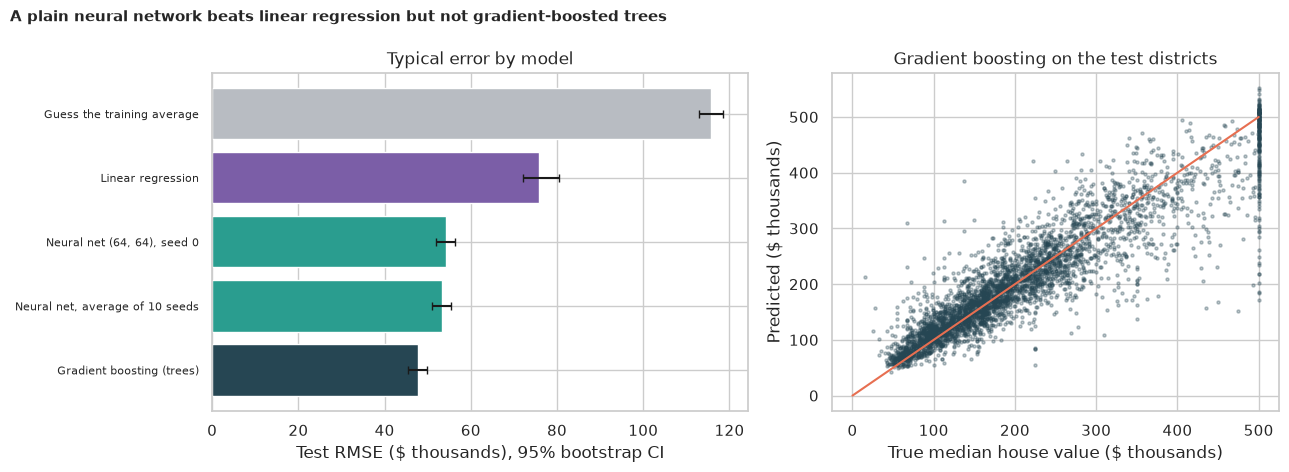

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
shown = model_table.iloc[::-1]
colors = {"Guess": GREY, "Linear": PURPLE, "Neural": TEAL, "Gradient": NAVY}
bar_colors = [next(c for k, c in colors.items() if name.startswith(k)) for name in shown.index]
ypos = np.arange(len(shown))
axes[0].barh(
    ypos,
    shown["rmse"] * 100,
    color=bar_colors,
    xerr=[(shown["rmse"] - shown["ci_low"]) * 100, (shown["ci_high"] - shown["rmse"]) * 100],
    capsize=3,
)
axes[0].set_yticks(ypos, shown.index, fontsize=8)
axes[0].set_xlabel("Test RMSE ($ thousands), 95% bootstrap CI")
axes[0].set_title("Typical error by model")

best_pred = preds["Gradient boosting (trees)"]
axes[1].scatter(y_test * 100, best_pred * 100, s=5, alpha=0.3, color=NAVY)
axes[1].plot([0, cap * 100], [0, cap * 100], color=ORANGE, lw=1.5)
axes[1].set_xlabel("True median house value ($ thousands)")
axes[1].set_ylabel("Predicted ($ thousands)")
axes[1].set_title("Gradient boosting on the test districts")
fig.suptitle(
    "A plain neural network beats linear regression but not gradient-boosted trees",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "03_models.png", dpi=150)
plt.show()

**How to read this:**

- **Test RMSE and R²:** guessing the average **1.156** (R² 0.00); linear regression **0.758** (R² 0.570); neural network seed 0 **0.541**; neural network ensemble **0.532** (R² **0.788**); gradient boosting **0.477** (R² **0.830**).
- **The network clearly beats linear regression:** linear minus network is **+0.226** (95% CI **+0.195 to +0.271**). The "combinations" the hidden layers build are worth about $23k of typical error.
- **But gradient boosting beats the network:** the difference (boosting minus network) is **-0.055** (CI **-0.068 to -0.042**), so boosting's error is lower by about **$5k** and the interval excludes 0. We **reject H₀** in both comparisons, in opposite directions.
- **Averaging 10 trainings helps only a little** (0.532 against 0.541 for one), so the network is not unstable; the remaining gap to trees is about how the models carve up the map, not luck.
- So for this kind of tabular data, the "obvious" deep-learning answer is **not the best one**, which is why a simple, strong baseline belongs in every project.

## 9. H4: does the size of the network matter?

*What:* the legacy notebook tried three shapes: a **baseline** (one layer of 13 units), a **larger** one (13 then 6) and a **wider** one (20). On our 8 features the same ideas become **`(8)`**, **`(8, 4)`** and **`(20)`**. We add our **reference `(64, 64)`** and a **deeper `(128, 128, 64)`**, train each with **5 seeds**, and compare the test RMSE. Kruskal-Wallis asks whether the architectures differ at all (with ε² as effect size), and paired seeds ask how each compares with the baseline.

*Why:* in the legacy notebook the three models were compared by a single run each, so nobody could tell a real improvement from seed noise.

In [10]:
ARCHITECTURES = {
    "legacy baseline (8)": (8,),
    "legacy larger (8, 4)": (8, 4),
    "legacy wider (20)": (20,),
    f"reference {REFERENCE_LAYERS}": REFERENCE_LAYERS,
    "deeper (128, 128, 64)": (128, 128, 64),
}
arch_rows = []
for name, hidden in ARCHITECTURES.items():
    for seed in range(N_SEEDS_ARCH):
        model = (
            std_models[seed]
            if hidden == REFERENCE_LAYERS
            else fit_mlp(Z_train, Z_val, hidden, seed)[0]
        )
        arch_rows.append(
            {
                "architecture": name,
                "seed": seed,
                "weights": sum(p.numel() for p in model.parameters()),
                "rmse": rmse(predict(model, Z_test), y_test),
            }
        )
arch = pd.DataFrame(arch_rows)
arch_summary = arch.groupby("architecture", sort=False).agg(
    weights=("weights", "first"),
    mean_rmse=("rmse", "mean"),
    sd=("rmse", "std"),
    best=("rmse", "min"),
    worst=("rmse", "max"),
)
print(arch_summary.round(3).to_string())
kw = stats.kruskal(*[g["rmse"].to_numpy() for _, g in arch.groupby("architecture")])
n_arch = len(ARCHITECTURES)
eps2 = (kw.statistic - n_arch + 1) / (len(arch) - n_arch)
print(
    f"\nKruskal-Wallis across architectures: H = {kw.statistic:.1f}, p = {kw.pvalue:.4f}, "
    f"epsilon^2 = {eps2:.2f}"
)
base = arch[arch["architecture"] == "legacy baseline (8)"].sort_values("seed")["rmse"].to_numpy()
for name in list(ARCHITECTURES)[1:]:
    other = arch[arch["architecture"] == name].sort_values("seed")["rmse"].to_numpy()
    print(
        f"  {name} vs baseline: RMSE change {np.mean(other - base):+.3f} "
        f"(lower in {(other < base).sum()} of {N_SEEDS_ARCH} paired seeds)"
    )

                       weights  mean_rmse     sd   best  worst
architecture                                                  
legacy baseline (8)         81      0.647  0.008  0.634  0.656
legacy larger (8, 4)       113      0.624  0.005  0.617  0.630
legacy wider (20)          201      0.616  0.008  0.607  0.628
reference (64, 64)        4801      0.539  0.004  0.533  0.541
deeper (128, 128, 64)    25985      0.529  0.002  0.527  0.532

Kruskal-Wallis across architectures: H = 22.3, p = 0.0002, epsilon^2 = 0.92
  legacy larger (8, 4) vs baseline: RMSE change -0.022 (lower in 5 of 5 paired seeds)
  legacy wider (20) vs baseline: RMSE change -0.030 (lower in 5 of 5 paired seeds)
  reference (64, 64) vs baseline: RMSE change -0.108 (lower in 5 of 5 paired seeds)
  deeper (128, 128, 64) vs baseline: RMSE change -0.117 (lower in 5 of 5 paired seeds)


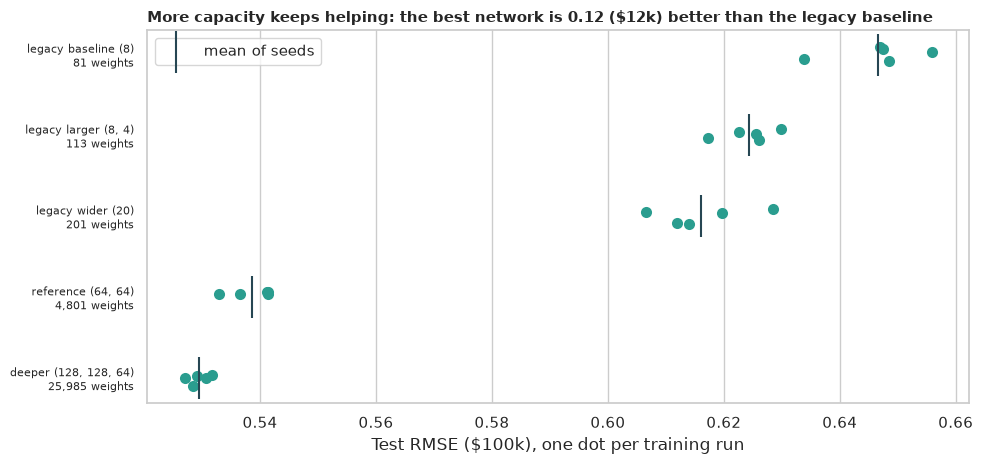

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.8))
order = list(ARCHITECTURES)
sns.stripplot(data=arch, y="architecture", x="rmse", order=order, color=TEAL, size=8, ax=ax)
ax.scatter(
    arch_summary["mean_rmse"],
    np.arange(len(order)),
    marker="|",
    s=900,
    color=NAVY,
    zorder=3,
    label="mean of seeds",
)
ax.set_yticks(
    np.arange(len(order)),
    [f"{n}\n{arch_summary.loc[n, 'weights']:,} weights" for n in order],
    fontsize=8,
)
ax.set_xlabel("Test RMSE ($100k), one dot per training run")
ax.set_ylabel("")
gain = arch_summary["mean_rmse"].iloc[0] - arch_summary["mean_rmse"].min()
ax.set_title(
    f"More capacity keeps helping: the best network is {gain:.2f} (${gain * 100:.0f}k) "
    "better than the legacy baseline",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "04_architectures.png", dpi=150)
plt.show()

**How to read this:**

- **Size matters a lot:** the mean test RMSE falls from **0.647** (baseline, 81 weights) to **0.624** (larger, 113 weights), **0.616** (wider, 201), **0.539** (reference, 4,801) and **0.529** (deeper, 25,985). Kruskal-Wallis gives H = 22.3, **p = 0.0002**, ε² = **0.92**: a huge effect. **We reject H₀.**
- **Each architecture beats the baseline in all 5 paired seeds:** by 0.022, 0.030, 0.108 and 0.117 respectively.
- **The legacy "larger" vs "wider" contest is a draw:** 0.624 against 0.616 differs by 0.008, about the same as the seed-to-seed spread (0.005 to 0.008), so those three legacy networks cannot be told apart by this data. The real jump comes from going from tens or hundreds of weights to thousands.
- **Diminishing returns:** multiplying the reference network's weights by about five (to 25,985) gains only **0.010** more. The deeper network is also the most consistent (sd 0.002).

## 10. H5: where does the best model go wrong?

*What:* we examine the errors of the best model (gradient boosting) and of the network ensemble, on the test districts:

1. **On the map:** are the errors random, or do neighbouring districts share them? For each district we correlate its error with the average error of its **10 nearest neighbours**, and compare with what happens when the errors are **shuffled** across districts 1,000 times (a permutation test).
2. **At the ceiling:** do the 198 test districts recorded at $500k have larger errors than the rest (Mann-Whitney, Cliff's δ), and which direction are they wrong in?

*Why:* a model whose errors have structure is telling us what it is missing.

In [12]:
test_coords = housing.iloc[test_idx][["Latitude", "Longitude"]].to_numpy()
residual = y_test - preds["Gradient boosting (trees)"]
nn_residual = y_test - preds[ens_name]
nbrs = NearestNeighbors(n_neighbors=11).fit(test_coords)
neighbour_ids = nbrs.kneighbors(test_coords, return_distance=False)[:, 1:]


def neighbour_correlation(res: np.ndarray) -> float:
    """Correlation between each district's error and the mean error of its 10 nearest districts.

    Args:
        res: Residuals for the test districts.

    Returns:
        The Pearson correlation.
    """
    return float(np.corrcoef(res, res[neighbour_ids].mean(axis=1))[0, 1])


spatial_rows = []
for label, res in [("Gradient boosting", residual), ("Neural net ensemble", nn_residual)]:
    observed = neighbour_correlation(res)
    null = np.array([neighbour_correlation(rng.permutation(res)) for _ in range(1_000)])
    p = (1 + (null >= observed).sum()) / (1 + len(null))
    spatial_rows.append(
        {
            "model": label,
            "neighbour correlation": observed,
            "largest shuffled value": null.max(),
            "p": p,
        }
    )
print(pd.DataFrame(spatial_rows).set_index("model").round(3).to_string())

is_capped = y_test >= cap
abs_err = np.abs(residual)
mw = stats.mannwhitneyu(abs_err[is_capped], abs_err[~is_capped])
cliff = 2 * mw.statistic / (is_capped.sum() * (~is_capped).sum()) - 1
print(
    f"\nGradient boosting, test districts at the ceiling ({is_capped.sum()}) vs the rest "
    f"({(~is_capped).sum():,}):"
)
print(
    f"  median absolute error ${np.median(abs_err[is_capped]) * 100:.0f}k vs "
    f"${np.median(abs_err[~is_capped]) * 100:.0f}k; Mann-Whitney p = {fmt_p(mw.pvalue)}, "
    f"Cliff's delta = {cliff:.2f}"
)
print(
    f"  mean error (truth minus prediction) at the ceiling: "
    f"{residual[is_capped].mean() * 100:+.0f}k"
)

                     neighbour correlation  largest shuffled value      p
model                                                                    
Gradient boosting                    0.249                   0.098  0.001
Neural net ensemble                  0.435                   0.090  0.001

Gradient boosting, test districts at the ceiling (198) vs the rest (3,930):
  median absolute error $30k vs $20k; Mann-Whitney p = 3.4e-06, Cliff's delta = 0.20
  mean error (truth minus prediction) at the ceiling: +50k


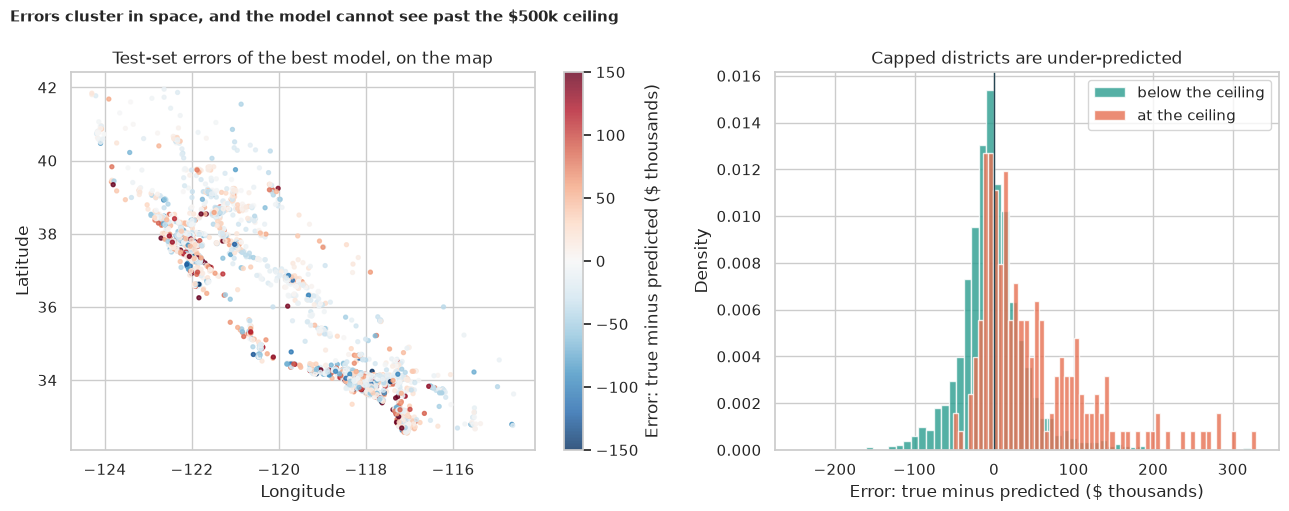

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
limit = 1.5
sc = axes[0].scatter(
    test_coords[:, 1],
    test_coords[:, 0],
    c=residual * 100,
    cmap="RdBu_r",
    vmin=-limit * 100,
    vmax=limit * 100,
    s=8,
    alpha=0.8,
)
fig.colorbar(sc, ax=axes[0], label="Error: true minus predicted ($ thousands)")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].set_title("Test-set errors of the best model, on the map")
axes[1].hist(
    residual[~is_capped] * 100,
    bins=60,
    color=TEAL,
    alpha=0.8,
    density=True,
    label="below the ceiling",
)
axes[1].hist(
    residual[is_capped] * 100,
    bins=60,
    color=ORANGE,
    alpha=0.8,
    density=True,
    label="at the ceiling",
)
axes[1].axvline(0, color=NAVY, lw=1)
axes[1].set_xlabel("Error: true minus predicted ($ thousands)")
axes[1].set_ylabel("Density")
axes[1].set_title("Capped districts are under-predicted")
axes[1].legend()
fig.suptitle(
    "Errors cluster in space, and the model cannot see past the $500k ceiling",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "05_errors.png", dpi=150)
plt.show()

**How to read this:**

- **Errors are not random on the map.** The correlation of a district's error with its neighbours' is **0.249** for gradient boosting and **0.435** for the network ensemble, while the largest value over 1,000 shuffles is only about **0.09 to 0.10** (permutation p = 0.001, the smallest value 1,000 shuffles can give). **We reject H₀:** whole neighbourhoods are over- or under-estimated together.
- **The network is worse in space than the trees:** 0.435 against 0.249. A likely reason (not tested here) is that trees can cut the map into sharp patches, while a smooth network is slower to learn that two places a few miles apart are priced very differently. Good location features, such as distance to the coast or to a big city, are the obvious next experiment.
- **The ceiling hurts:** at the $500k ceiling the median absolute error is **$30k** against **$20k** elsewhere (Mann-Whitney p = 3e-6, Cliff's δ = 0.20), and the model **under-predicts these districts by $50k on average**. It was trained on a ceiling, so it cannot predict above one.
- The right-hand histogram shows the two error distributions: the orange ceiling districts sit to the right of zero (the truth is higher than predicted).

## 11. 🎯 Takeaways

1. **Income is the main driver** of house value (ρ = 0.677), with location next; population does not matter (ρ = 0.004).
2. **Standardise the inputs.** It cut test error from 0.783 to 0.540 (about $24k) and won in 10 of 10 seeds. The legacy notebook built a standardising pipeline and never used it.
3. **The network beats linear regression** (RMSE 0.532 against 0.758) **but not gradient-boosted trees** (0.477): the tree ensemble is the better tool for this table.
4. **Size matters until it doesn't:** the legacy shapes (81 to 201 weights) are barely distinguishable (0.616 to 0.647), going to 4,801 weights drops error to 0.539, and a five-times-larger network adds only 0.010.
5. **Errors have a geography and a ceiling.** Neighbouring districts share their errors (0.249 to 0.435 correlation, against about 0.09 by chance), and districts recorded at $500k are under-predicted by $50k on average.

## 12. ⚠️ Limitations

- **A random split flatters the models.** Neighbouring districts have similar prices and sit on both sides of the split, so the test scores are optimistic compared with predicting a district in a region the model has never seen. A geographic split would be a stricter test.
- **One split and one dataset.** The test intervals reflect sampling of districts and training seeds (10 for H2 and H3, 5 for H4) but not a different split of the data. With 5 or 10 seeds some p-values sit at their minimum possible value.
- **The data are from the 1990 census.** Absolute prices are long out of date; the patterns (income, location, the ceiling) are the lesson.
- **District averages, not houses.** Each row is a neighbourhood summary, so these models say nothing about an individual home.
- **The training budget was fixed** (80 epochs); the reference network was still improving at epoch 73, so longer training or tuning might narrow the gap to gradient boosting. We did not tune either family, only used sensible defaults.
- **Ceiling districts were kept as they are.** Treating the ceiling properly (as censored data) is a modelling topic of its own.